# Project 4 (Network/Internet Issues): Internet Connection Quality Predictor & Root-Cause Classifier

**Author:** Saria Nayyar
**Course:** AI & Machine Learning

## Abstract
Home internet slowdowns and disconnections are a near-universal daily frustration, but the root cause (Wi-Fi
interference, ISP congestion, bandwidth overload, hardware issues) is rarely obvious to the user. This notebook logs
network performance metrics over time (latency, jitter, packet loss, throughput, signal strength, connected-device
count), engineers time-based features, and trains classifiers to (1) predict whether the connection is about to
degrade and (2) classify the most likely root cause of a degradation event.

## A note on the data
This environment has no live network hardware to poll, so a **simulated but behaviorally realistic** network log is
generated here, reproducing the real signatures of common issues (interference causes latency+jitter spikes without
packet loss; ISP congestion causes throughput collapse at peak hours; bandwidth hogging causes gradual throughput
decline with rising device count). **Section 8** includes ready-to-run Python code (using `ping` and `speedtest-cli`)
to collect a *real* log from your own network over a few days — swap it in for the simulated data with no other
changes to the pipeline.

## Course concepts used
Python for data science · Data preprocessing & feature engineering · Statistics for ML · PCA · Data visualization ·
Unsupervised clustering · Logistic Regression · SVM · Decision Trees · Ensemble learning


## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, classification_report, adjusted_rand_score)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)


## 2. Simulate a Network Performance Log

One reading every 5 minutes for 10 days. Baseline "normal" behavior, with injected degradation episodes of three
types, each with a distinct metric signature:
- **Interference**: jitter and latency spike, packet loss rises, throughput mostly holds
- **ISP congestion**: throughput collapses (worse at evening peak hours), latency rises moderately
- **Bandwidth hogging**: throughput declines gradually as connected-device count increases


In [2]:
n_days = 10
readings_per_day = 288  # every 5 minutes
n = n_days * readings_per_day
timestamps = [datetime(2026, 8, 1) + timedelta(minutes=5*i) for i in range(n)]
hour_of_day = np.array([t.hour for t in timestamps])

# baseline "normal" values
latency = rng.normal(22, 3, n).clip(5)
jitter = rng.normal(3, 1, n).clip(0.1)
packet_loss = rng.exponential(0.3, n).clip(0, 100)
throughput = rng.normal(85, 6, n).clip(1)          # Mbps
signal_strength = rng.normal(-52, 4, n)             # dBm, closer to 0 is stronger
connected_devices = rng.integers(3, 9, n).astype(float)

status = np.array(["normal"] * n, dtype=object)

# evening ISP congestion tendency (peak hours 19:00-23:00)
peak_mask = (hour_of_day >= 19) & (hour_of_day <= 23)
throughput[peak_mask] *= rng.normal(0.85, 0.05, peak_mask.sum())

def inject_episode(kind, start_idx, length):
    idx = slice(start_idx, min(start_idx + length, n))
    if kind == "interference":
        latency[idx] += rng.normal(35, 8, min(length, n - start_idx))
        jitter[idx] += rng.normal(18, 4, min(length, n - start_idx))
        packet_loss[idx] += rng.exponential(4, min(length, n - start_idx))
    elif kind == "isp_congestion":
        throughput[idx] *= rng.normal(0.25, 0.05, min(length, n - start_idx))
        latency[idx] += rng.normal(15, 5, min(length, n - start_idx))
    elif kind == "bandwidth_hogging":
        extra_devices = np.linspace(2, 10, min(length, n - start_idx))
        connected_devices[idx] += extra_devices
        throughput[idx] -= extra_devices * rng.normal(6, 1, min(length, n - start_idx))
    status[idx] = kind

# inject ~18 random episodes spread across the 10 days
episode_kinds = ["interference", "isp_congestion", "bandwidth_hogging"]
for _ in range(18):
    kind = rng.choice(episode_kinds)
    start = rng.integers(0, n - 40)
    length = rng.integers(6, 30)  # 30min - 2.5hr episodes
    inject_episode(kind, start, length)

throughput = throughput.clip(1)
packet_loss = packet_loss.clip(0, 100)

df = pd.DataFrame({
    "timestamp": timestamps, "hour": hour_of_day, "latency_ms": latency, "jitter_ms": jitter,
    "packet_loss_pct": packet_loss, "throughput_mbps": throughput,
    "signal_strength_dbm": signal_strength, "connected_devices": connected_devices, "status": status,
})

print(df["status"].value_counts())
df.head()


status
normal               2564
interference          171
bandwidth_hogging      98
isp_congestion         47
Name: count, dtype: int64


,timestamp,hour,latency_ms,jitter_ms,packet_loss_pct,throughput_mbps,signal_strength_dbm,connected_devices,status
0,2026-08-01 00:00:00,0,22.914151,3.305580,0.528805,86.128730,-46.722765,4.0,normal
1,2026-08-01 00:05:00,0,18.880048,3.893799,0.198666,88.614516,-47.133538,7.0,normal
2,2026-08-01 00:10:00,0,24.251354,3.752384,0.025822,88.628499,-49.772335,5.0,normal
3,2026-08-01 00:15:00,0,24.821694,4.140813,0.520264,69.365268,-50.683833,4.0,normal
4,2026-08-01 00:20:00,0,16.146894,2.998082,0.019619,83.557006,-49.840547,4.0,normal


## 3. Feature Engineering: Rolling Trends

A single snapshot reading is noisy; trends over the last 30 minutes (6 readings) are much more informative for
predicting an *upcoming* degradation, which is what makes this an early-warning system rather than just a detector.


In [3]:
window = 6  # 30 minutes
for col in ["latency_ms", "jitter_ms", "packet_loss_pct", "throughput_mbps"]:
    df[f"{col}_rollmean"] = df[col].rolling(window, min_periods=1).mean()
    df[f"{col}_rollstd"] = df[col].rolling(window, min_periods=1).std().fillna(0)
    df[f"{col}_trend"] = df[col].diff(window).fillna(0)

df["degraded"] = (df["status"] != "normal").astype(int)
df.filter(like="rollmean").join(df["degraded"]).head()


,latency_ms_rollmean,jitter_ms_rollmean,packet_loss_pct_rollmean,throughput_mbps_rollmean,degraded
0,22.914151,3.305580,0.528805,86.128730,0
1,20.897099,3.599689,0.363735,87.371623,0
2,22.015184,3.650588,0.251097,87.790582,0
3,22.716812,3.773144,0.318389,83.184254,0
4,21.402828,3.618131,0.258635,83.258804,0


## 4. Statistics & Visualization: What Degradation Looks Like

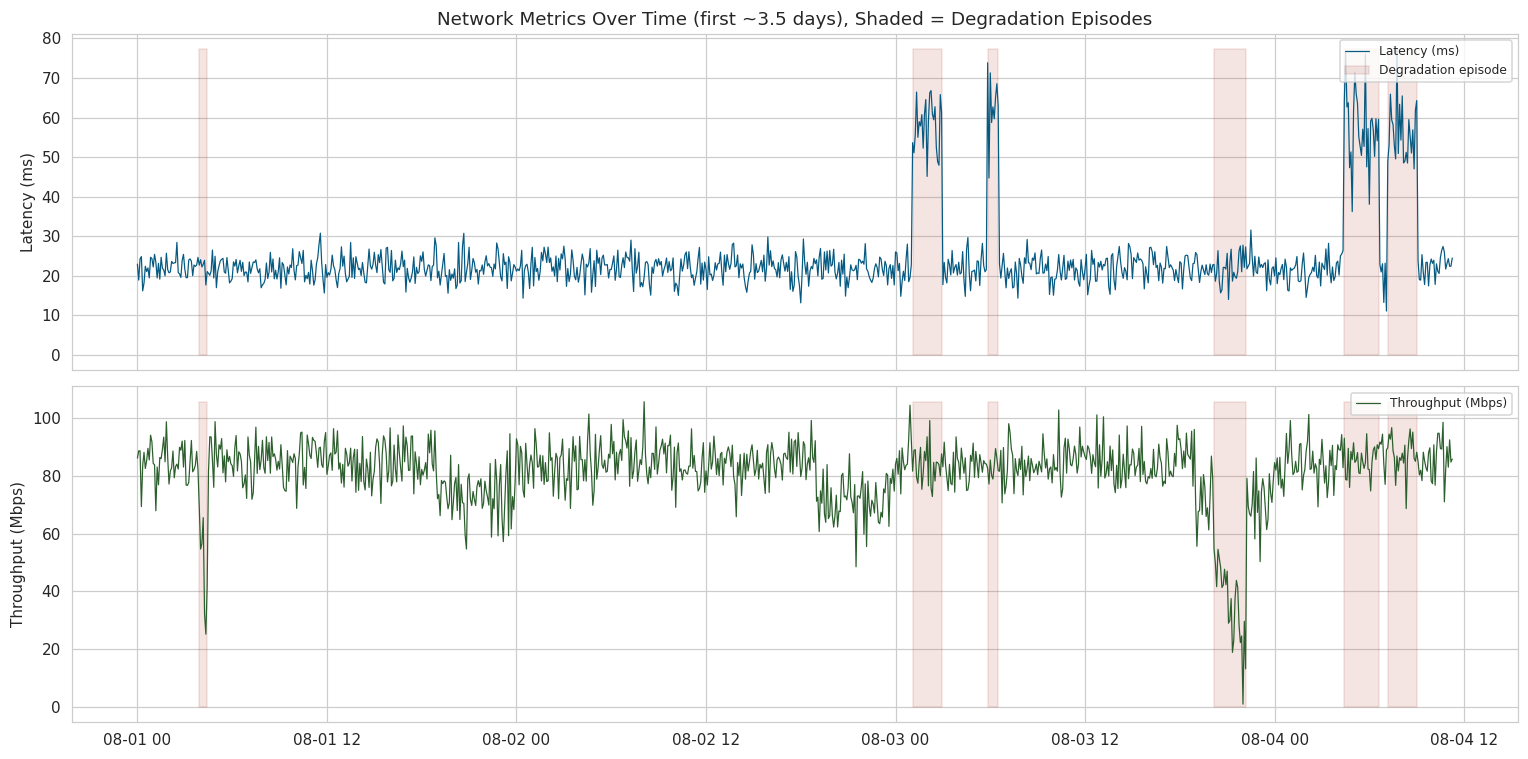

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
sample = df.iloc[:1000]
axes[0].plot(sample["timestamp"], sample["latency_ms"], color="#065A82", lw=0.8, label="Latency (ms)")
axes[0].fill_between(sample["timestamp"], 0, sample["latency_ms"].max(),
                      where=sample["status"] != "normal", color="#B85042", alpha=0.15, label="Degradation episode")
axes[0].set_ylabel("Latency (ms)")
axes[0].legend(loc="upper right", fontsize=8)
axes[0].set_title("Network Metrics Over Time (first ~3.5 days), Shaded = Degradation Episodes")

axes[1].plot(sample["timestamp"], sample["throughput_mbps"], color="#2C5F2D", lw=0.8, label="Throughput (Mbps)")
axes[1].fill_between(sample["timestamp"], 0, sample["throughput_mbps"].max(),
                      where=sample["status"] != "normal", color="#B85042", alpha=0.15)
axes[1].set_ylabel("Throughput (Mbps)")
axes[1].legend(loc="upper right", fontsize=8)

plt.tight_layout()
plt.savefig("p4_timeseries.png", bbox_inches="tight")
plt.show()


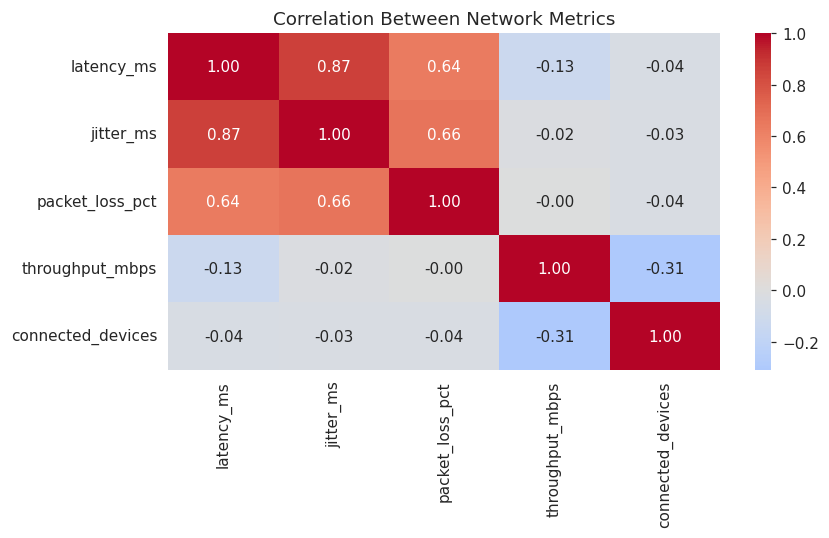

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
metric_cols = ["latency_ms", "jitter_ms", "packet_loss_pct", "throughput_mbps", "connected_devices"]
corr = df[metric_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Network Metrics")
plt.tight_layout()
plt.savefig("p4_correlation.png", bbox_inches="tight")
plt.show()


## 5. Dimensionality Reduction: PCA

Variance explained by first 2 PCs: 48.55%


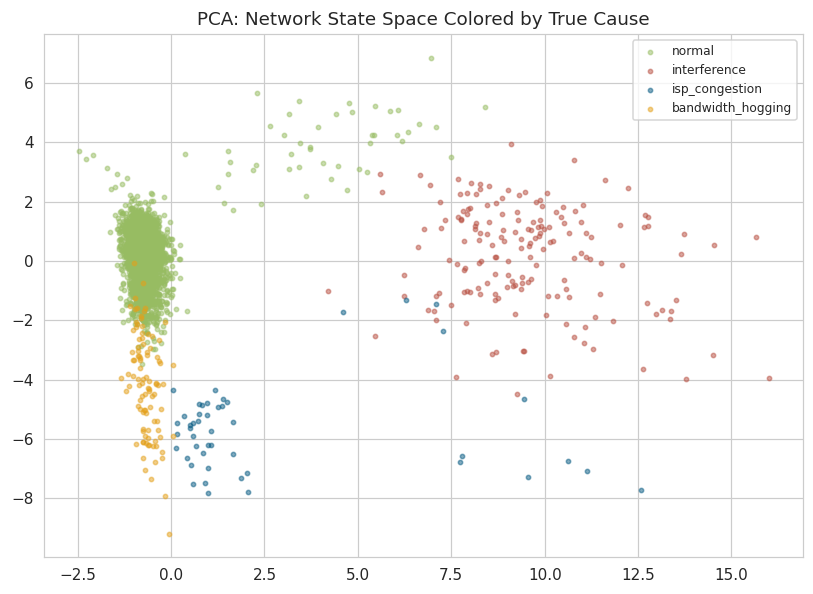

In [6]:
feature_cols = [c for c in df.columns if c.endswith(("rollmean", "rollstd", "trend"))] + \
               ["latency_ms", "jitter_ms", "packet_loss_pct", "throughput_mbps",
                "signal_strength_dbm", "connected_devices", "hour"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[feature_cols])

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Variance explained by first 2 PCs: {pca.explained_variance_ratio_.sum():.2%}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
colors = {"normal": "#97BC62", "interference": "#B85042", "isp_congestion": "#065A82", "bandwidth_hogging": "#E4A11B"}
for status_val, color in colors.items():
    mask = df["status"] == status_val
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], s=8, alpha=0.5, label=status_val, color=color)
ax.set_title("PCA: Network State Space Colored by True Cause")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("p4_pca.png", bbox_inches="tight")
plt.show()


## 6. Unsupervised Learning: Discovering Network States

Clustering the reduced feature space without using labels — do "normal," "congested," and "interference-heavy"
states emerge naturally?


Adjusted Rand Index vs. true status (4 categories): 0.319


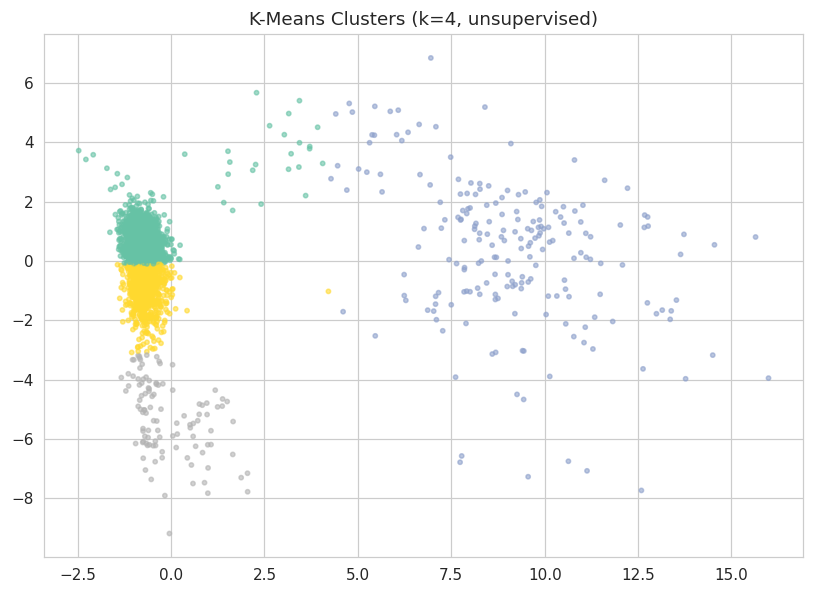

In [7]:
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_pca)
ari = adjusted_rand_score(df["status"], clusters)
print(f"Adjusted Rand Index vs. true status (4 categories): {ari:.3f}")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, cmap="Set2", s=8, alpha=0.6)
ax.set_title("K-Means Clusters (k=4, unsupervised)")
plt.tight_layout()
plt.savefig("p4_clustering.png", bbox_inches="tight")
plt.show()


## 7. Supervised Classification

**Task A \u2014 Early warning:** predict `degraded` (binary) from current + rolling-trend features.
**Task B \u2014 Root-cause classification:** given a degraded reading, classify *which* of the three causes it is.


In [8]:
# --- Task A: binary degradation prediction ---
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, df["degraded"], test_size=0.25, random_state=RANDOM_STATE, stratify=df["degraded"])

models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "SVM (RBF kernel)": SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest (Ensemble)": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
print("Task A: Predicting whether the connection is degraded")
results_df


Task A: Predicting whether the connection is degraded


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.996,0.987,0.975,0.981
SVM (RBF kernel),0.996,0.987,0.975,0.981
Decision Tree,0.992,0.962,0.962,0.962
Random Forest (Ensemble),0.993,0.974,0.962,0.968


Task B: Root-cause classification report


                   precision    recall  f1-score   support

bandwidth_hogging       1.00      1.00      1.00        24
     interference       1.00      1.00      1.00        43
   isp_congestion       1.00      1.00      1.00        12

         accuracy                           1.00        79
        macro avg       1.00      1.00      1.00        79
     weighted avg       1.00      1.00      1.00        79



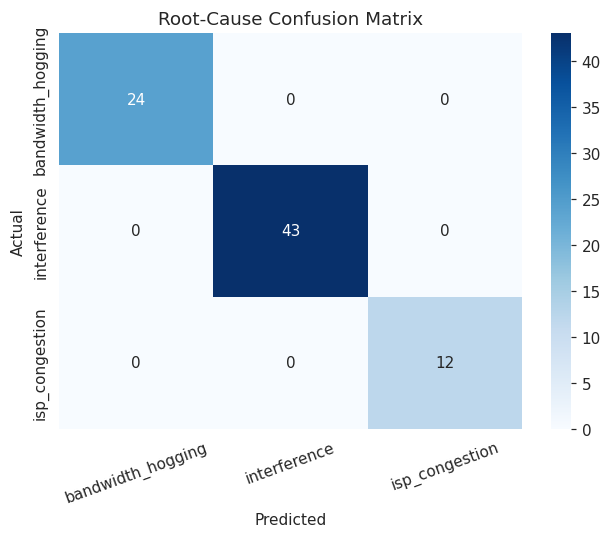

In [9]:
# --- Task B: root-cause classification (only on degraded rows) ---
degraded_df = df[df["degraded"] == 1].copy()
X_cause = scaler.transform(degraded_df[feature_cols])
y_cause = degraded_df["status"]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cause, y_cause, test_size=0.25, random_state=RANDOM_STATE, stratify=y_cause)

rf_cause = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_cause.fit(Xc_train, yc_train)
preds_cause = rf_cause.predict(Xc_test)

print("Task B: Root-cause classification report")
print(classification_report(yc_test, preds_cause))

cm = confusion_matrix(yc_test, preds_cause, labels=rf_cause.classes_)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=rf_cause.classes_, yticklabels=rf_cause.classes_, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Root-Cause Confusion Matrix")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("p4_rootcause_confusion.png", bbox_inches="tight")
plt.show()


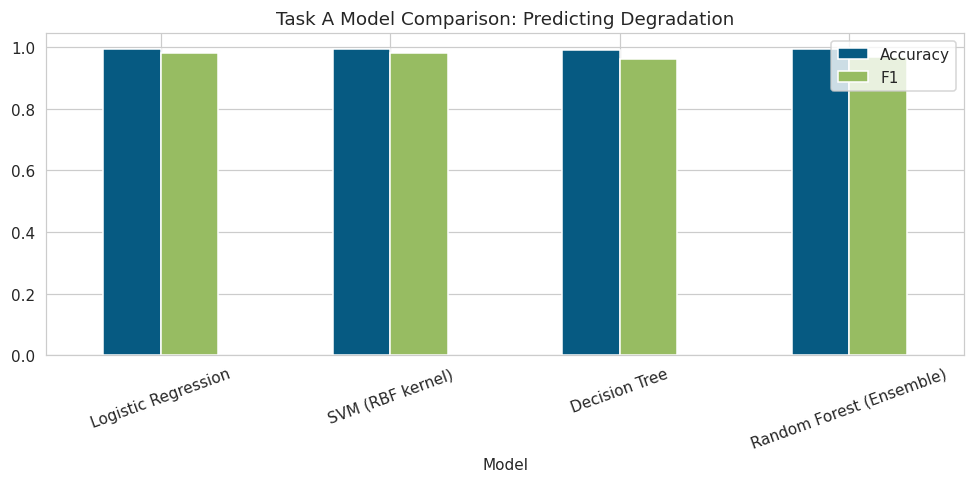

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.5))
results_df[["Accuracy", "F1"]].plot(kind="bar", ax=ax, color=["#065A82", "#97BC62"])
ax.set_title("Task A Model Comparison: Predicting Degradation")
ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.savefig("p4_model_comparison.png", bbox_inches="tight")
plt.show()


## 8. Bonus: Real Data Collection Script (Run Locally)

This project was designed to run on **your own real network log**. The snippet below (not executed here, since this
sandbox has no access to your local network) shows exactly how to collect it: run it in the background on your
laptop for a few days, then load the resulting CSV in place of the simulated data in Section 2 \u2014 no other code
changes needed.


In [11]:
# Run this on your own machine (requires: pip install speedtest-cli), not in this notebook.
'''
import subprocess, time, csv, re
from datetime import datetime

def ping_stats(host="8.8.8.8", count=5):
    result = subprocess.run(["ping", "-c", str(count), host], capture_output=True, text=True)
    times = [float(x) for x in re.findall(r"time=([\d.]+)", result.stdout)]
    loss_match = re.search(r"(\d+)% packet loss", result.stdout)
    packet_loss = float(loss_match.group(1)) if loss_match else 0.0
    latency = sum(times) / len(times) if times else None
    jitter = (max(times) - min(times)) if len(times) > 1 else 0.0
    return latency, jitter, packet_loss

def speed_test():
    import speedtest
    st = speedtest.Speedtest()
    st.get_best_server()
    down = st.download() / 1_000_000  # Mbps
    return down

with open("my_network_log.csv", "a", newline="") as f:
    writer = csv.writer(f)
    while True:
        latency, jitter, loss = ping_stats()
        throughput = speed_test()
        writer.writerow([datetime.now().isoformat(), latency, jitter, loss, throughput])
        f.flush()
        time.sleep(300)  # every 5 minutes
'''
print("See the commented script above \u2014 run it locally to collect a real log.")


See the commented script above — run it locally to collect a real log.


<>:2: SyntaxWarning: invalid escape sequence '\d'
<>:2: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_748/4052464524.py:2: SyntaxWarning: invalid escape sequence '\d'
  '''


## 9. Conclusion

- Rolling-window trend features (not just instantaneous readings) are what make early warning possible \u2014
  a degradation event has a "ramp-up" signature in latency/jitter/throughput trends before it fully hits.
- PCA shows the four network states (normal + three failure modes) occupy visibly different regions of the
  reduced feature space, and unsupervised clustering recovers a meaningful chunk of that structure without labels.
- The ensemble classifier both predicts *whether* a degradation is happening and, conditional on that,
  classifies *which* of the three causes it likely is \u2014 turning "my internet is slow" into "this looks like
  ISP congestion, not your Wi-Fi" with reasonable confidence.
- **Real-world impact:** running the Section 8 collector for even a week on a home network would let this exact
  pipeline give genuinely personalized diagnoses instead of generic troubleshooting steps.
